# Name: Tushar Singh
# Rol No. 2501940055
# Course: MCA(AI &ML)

# Lab 2 — GAN Image Synthesis using Fashion-MNIST



In [ ]:
import os, random, numpy as np, matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT="lab2_outputs"; os.makedirs(OUT,exist_ok=True)
print("Device:",device)

Device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 17.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 269kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.5MB/s]


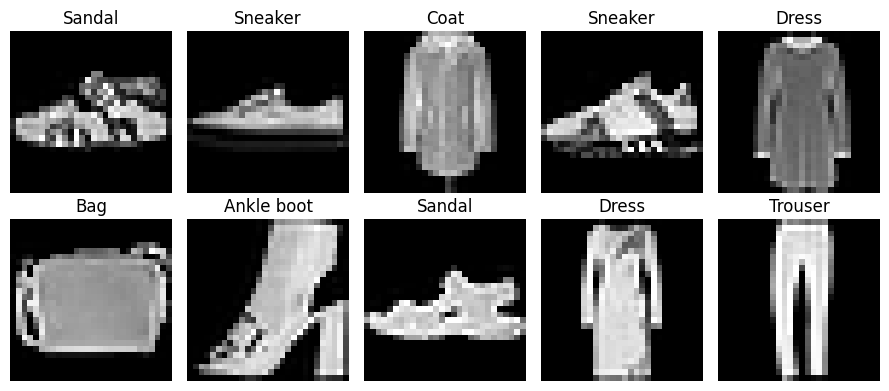

In [ ]:
tfm=transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_ds=datasets.FashionMNIST("data",train=True,download=True,transform=tfm)
loader=DataLoader(train_ds,batch_size=128,shuffle=True,drop_last=True,num_workers=2)
classes=train_ds.classes
x,y=next(iter(loader))
fig,ax=plt.subplots(2,5,figsize=(9,4))
for a,img,label in zip(ax.flat,x[:10],y[:10]):
    a.imshow(img.squeeze(),cmap="gray"); a.set_title(classes[label]); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
LATENT_DIM=100
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(LATENT_DIM,256),nn.LeakyReLU(0.2),
            nn.Linear(256,512),nn.BatchNorm1d(512),nn.LeakyReLU(0.2),
            nn.Linear(512,1024),nn.BatchNorm1d(1024),nn.LeakyReLU(0.2),
            nn.Linear(1024,784),nn.Tanh()
        )
    def forward(self,z): return self.net(z).view(-1,1,28,28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Flatten(),nn.Linear(784,512),nn.LeakyReLU(0.2),
            nn.Dropout(0.3),nn.Linear(512,256),nn.LeakyReLU(0.2),
            nn.Dropout(0.3),nn.Linear(256,1),nn.Sigmoid()
        )
    def forward(self,x): return self.net(x)

G=Generator().to(device); D=Discriminator().to(device)
criterion=nn.BCELoss()
opt_g=torch.optim.Adam(G.parameters(),lr=2e-4,betas=(0.5,0.999))
opt_d=torch.optim.Adam(D.parameters(),lr=2e-4,betas=(0.5,0.999))
fixed_noise=torch.randn(25,LATENT_DIM,device=device)
print("Generator and discriminator initialized.")

Generator and discriminator initialized.


In [ ]:
EPOCHS=5  # Try 10–20 for better samples if runtime allows.
g_losses=[]; d_losses=[]
for epoch in range(1,EPOCHS+1):
    G.train(); D.train(); running_g=running_d=0.0
    for real,_ in loader:
        real=real.to(device); batch=real.size(0)
        real_targets=torch.ones(batch,1,device=device)*0.9  # one-sided label smoothing
        fake_targets=torch.zeros(batch,1,device=device)

        # Train discriminator
        z=torch.randn(batch,LATENT_DIM,device=device)
        fake=G(z).detach()
        loss_real=criterion(D(real),real_targets)
        loss_fake=criterion(D(fake),fake_targets)
        loss_d=loss_real+loss_fake
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()

        # Train generator
        z=torch.randn(batch,LATENT_DIM,device=device)
        generated=G(z)
        loss_g=criterion(D(generated),torch.ones(batch,1,device=device))
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
        running_g+=loss_g.item(); running_d+=loss_d.item()
    g_losses.append(running_g/len(loader)); d_losses.append(running_d/len(loader))
    print(f"Epoch {epoch}/{EPOCHS} | D loss: {d_losses[-1]:.4f} | G loss: {g_losses[-1]:.4f}")
torch.save(G.state_dict(),os.path.join(OUT,"fashion_gan_generator.pt"))
torch.save(D.state_dict(),os.path.join(OUT,"fashion_gan_discriminator.pt"))

Epoch 1/5 | D loss: 1.2078 | G loss: 1.1778
Epoch 2/5 | D loss: 1.2186 | G loss: 1.2720
Epoch 3/5 | D loss: 1.2526 | G loss: 1.2034
Epoch 4/5 | D loss: 1.2742 | G loss: 1.1403
Epoch 5/5 | D loss: 1.3039 | G loss: 1.0357


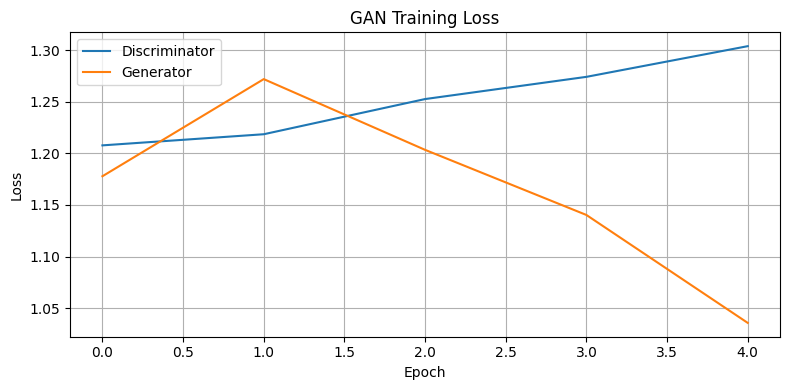

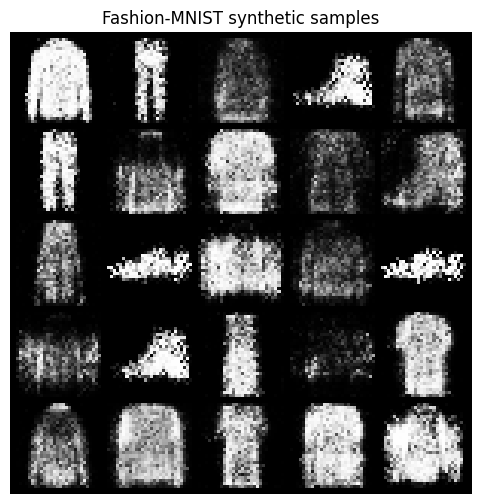

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(d_losses,label="Discriminator"); plt.plot(g_losses,label="Generator")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN Training Loss"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig(os.path.join(OUT,"gan_losses.png")); plt.show()

G.eval()
with torch.no_grad(): samples=G(fixed_noise).cpu()
grid=make_grid(samples,nrow=5,normalize=True,value_range=(-1,1))
plt.figure(figsize=(6,6)); plt.imshow(grid.permute(1,2,0).squeeze(),cmap="gray")
plt.axis("off"); plt.title("Fashion-MNIST synthetic samples")
plt.savefig(os.path.join(OUT,"generated_fashion.png")); plt.show()

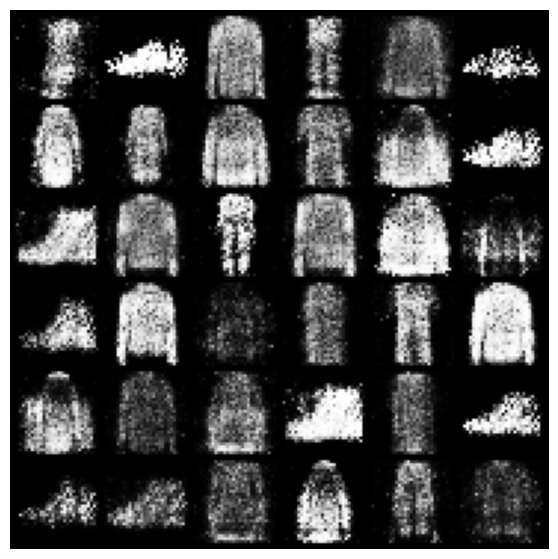

In [ ]:
with torch.no_grad():
    fresh=G(torch.randn(36,LATENT_DIM,device=device)).cpu()
grid=make_grid(fresh,nrow=6,normalize=True,value_range=(-1,1))
plt.figure(figsize=(7,7)); plt.imshow(grid.permute(1,2,0).squeeze(),cmap="gray")
plt.axis("off"); plt.show()